In [64]:
import matplotlib.pyplot as plt
import pandas as pd
import torch
import time
import sys
import os

from pathlib import Path
from dotenv import load_dotenv
from typing import List

# import local libs
cwd = Path.cwd()
ROOT = next(p for p in (cwd, *cwd.parents) if (p / "src").is_dir())
WEIGHTS = ROOT / "weights"

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.models.transformer_lm import GPTNeo
from transformers import AutoTokenizer
device = torch.device("cuda")

load_dotenv(ROOT / ".env")
DATA_DIR = Path(os.environ["TINYSTORIES_DIR"])

when using ChatGPT or Claude, we find that "inference speed", the speed in which responses are generated is generally quite fast. particularly due to the size of these models and the number of layers that exist, it is fairly impressive that a data center which may sit oceans between the user and the loaded weights can generate tokens at that speed.

a large part of this speed comes down to inference optimisation. before we do inference optimisation however, we look to first benchmark our models in tokens per second.

In [ ]:
model = GPTNeo(4, 10_000, 768, 512, [3024] * 4, [8] * 4, dropout=[0] * 4).to(device)
tokeniser = AutoTokenizer.from_pretrained(WEIGHTS / 'gpt-neo-10k-tokeniser');
state_dict = torch.load(WEIGHTS / '20260926_3024_4x_8_4x_0_4x_transformer.pt')
model.load_state_dict(state_dict)
model.eval();

the benchmark process works like this:
1. give some example prompt
2. synchronise the gpu; wait for all gpu calls to finish
3. generate a response for the given prompt, at each token mark the starting time
4. after a new token is generated, synchronise again, and then mark the difference between the time and starting time

In [ ]:
@torch.inference_mode()
def timed_generate(model, tokens: torch.tensor, max_new_tokens: int = 300, temperature: float = 0.75, context_length: int = 512) -> tuple[List[float], int]:
    step_times = []
    tokens_generated = 0

    # gpu calls run asynchronously so we need to wait for all gpu calls to finish before starting a new test
    torch.cuda.synchronize()
    for _ in range(max_new_tokens):
        t0 = time.perf_counter()

        logits = model(tokens[-context_length:].unsqueeze(0))[0, -1]
        probs = torch.softmax(logits / temperature, dim=-1)
        next_token = torch.multinomial(probs, num_samples=1)
        tokens = torch.cat([tokens, next_token])

        # wait for all gpu operations to finish up
        torch.cuda.synchronize()

        # get the time elapsed
        step_times.append(time.perf_counter() - t0)
        tokens_generated += 1

        # the eos token still cost a forward pass, so it is timed and counted before stopping
        if next_token.item() == tokeniser.eos_token_id: break

    return step_times, tokens_generated

def benchmark(model, tokens: torch.tensor, max_new_tokens: int = 300, warmup: int = 0, runs: int = 1):
    for _ in range(warmup): timed_generate(model, tokens, max_new_tokens=20)

    results = []
    for _ in range(runs):
        step_times, tokens_generated = timed_generate(model, tokens, max_new_tokens)
        seconds = sum(step_times)

        # divide by the tokens actually generated, as a story can end before max_new_tokens
        results.append({'tokens_generated': tokens_generated, 'seconds': seconds, 'tokens_per_sec': tokens_generated / seconds})

    return results

now benchmark inference speeds on the validation set; we choose 100 random prompts, and restrict the prompt length to 32 tokens to allow for like-for-like comparisons.

In [66]:
from src.data.dataset import LMDataset

valid_set = LMDataset(DATA_DIR / 'processed' / 'train_gpt_neo.bin', 512)

In [67]:
PROMPT_LEN = 32
generator = torch.Generator().manual_seed(0)
indices = torch.randperm(len(valid_set), generator=generator)[:100]

prompts = torch.stack([valid_set[i][0][:PROMPT_LEN] for i in indices.tolist()])

# the first few forward passes are slower, so run one throwaway generation before measuring
timed_generate(model, prompts[0].to(device), max_new_tokens=20)

samples = []
for p in prompts:
    p = p.to(device)
    samples.extend(benchmark(model, p))

samples = pd.DataFrame(samples)

what does the distribution of the model's inference speeds look like?

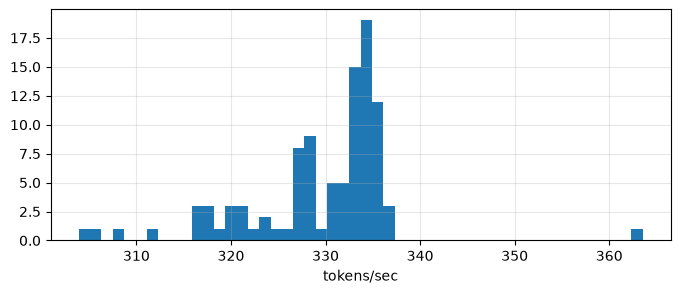

count    100.000000
mean     329.652112
std        7.882966
min      303.918820
25%      327.154670
50%      332.624083
75%      334.349971
max      363.520205
Name: tokens_per_sec, dtype: float64

In [71]:
plt.figure(figsize=(8, 3))
plt.hist(samples['tokens_per_sec'], bins = 50);
plt.grid(alpha=0.3)
plt.xlabel('tokens/sec')
plt.show()

samples['tokens_per_sec'].describe()

so we are at about on average ~329.65 tokens/sec; this is pretty good! but also, our model is many orders of magnitude smaller than frontier and open source models. since our model generates fairly small responses, it's unlikely that caching will help significantly; but i will try anyway!